Single allele groupped structue models.

In [1]:
from pomegranate import *

In [2]:
import numpy as np
amino_acids_list = list("ACDEFGHIKLMNPQRSTVWY")

d_dict = {key: prob for key, prob in zip(amino_acids_list, np.random.default_rng().uniform(0, 1, size=len(amino_acids_list)))}
aa_dist = DiscreteDistributionAnchor(d_dict)

In [3]:
position_variants = np.arange(0, 18)
pos_d_dict = {key: prob for key, prob in zip(position_variants, np.random.default_rng().uniform(0, 1, size=len(position_variants)))}
position_distribution = DiscreteDistribution(pos_d_dict)



In [4]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import logomaker
import sys
import seaborn as sns
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


 1. Read data

In [5]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
# DATA_PATH_BASE = 'D:/Google Drive/Work/ITMO/data' #windows
# DATA_PATH_BASE = '/home/denklewer/Data' #ubuntu

DATA_PATH = f'{DATA_PATH_BASE}/core_identification_paper/per_length_per_kfold_split/' # work laptop
TARGET_PATH_TO_RESULTS = "experiment_results/core_identification_paper/" #!CHANGE for bwv!

In [6]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
# per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
# per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

sorted(ALLELES)

['HLA-A*01:01',
 'HLA-A*02:01',
 'HLA-A*03:01',
 'HLA-A*24:02',
 'HLA-B*07:02',
 'HLA-B*15:02',
 'HLA-B*27:05',
 'HLA-B*57:01',
 'HLA-C*12:02',
 'HLA-DPA1*02:02/DPB1*05:01',
 'HLA-DQA1*05:01/DQB1*02:01',
 'HLA-DRB1*01:01',
 'HLA-DRB1*04:01',
 'HLA-DRB1*04:04',
 'HLA-DRB1*07:01']

In [7]:
get_available_alleles(DATA_PATH)

['HLA-DQA1*05:01/DQB1*02:01',
 'HLA-A*03:01',
 'HLA-B*15:02',
 'HLA-DRB1*07:01',
 'HLA-DPA1*02:02/DPB1*05:01',
 'HLA-DRB1*04:04',
 'HLA-C*12:02',
 'HLA-DRB1*01:01',
 'HLA-DRB1*04:01',
 'HLA-A*02:01',
 'HLA-B*57:01',
 'HLA-A*01:01',
 'HLA-B*07:02',
 'HLA-B*27:05',
 'HLA-A*24:02']

In [8]:
def make_logo_for_data(binders_array, name, ax=None):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True, ax=ax)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

# 2. Prepare data and weithgs for training
## 2.1 Merge alleles into combinations and define params

In [51]:

# Training params
algorithm = 'viterbi'
combination_size = 1
TOTAL_SPLITS = 5
NUM_RUNS = 2
USE_WEIGHTS = False
check_peptides = True

target_class = "class2_batches"

params = dict()


DataParams = {
"class1": {
    "ALLELES": sorted([ 'HLA-A*01:01','HLA-A*03:01']),
    "TARGET_LENGTHS":   [8, 9,10, 11, 12],
    'start_cycle': False,
    'end_cycle' :False,
    'intermediate_cycles' :True,
    'emission_pseudocount':50,
    'transition_pseudocount' : 0,
    'cycle_pseudocount' : 30,
    'anchor_top_aas':3,
    'anchor_default_pseudocount':50
},
    
"class2": {
    "ALLELES":sorted(['HLA-DPA1*02:02/DPB1*05:01']),
    "TARGET_LENGTHS":    [12, 13,14, 15, 16,17, 18],
    'start_cycle': True,
    'end_cycle' : True,
    'intermediate_cycles' :False,
    'emission_pseudocount':50,
    'transition_pseudocount' : 50,
    'cycle_pseudocount' : 300,
    'anchor_top_aas':6,
    'anchor_default_pseudocount': 50
    
},
    
    
    "class2_batches": {
    "ALLELES":sorted(['HLA-DPA1*02:02/DPB1*05:01']),
    "TARGET_LENGTHS":    [12, 13,14, 15, 16,17, 18],
    'start_cycle': True,
    'end_cycle' : True,
    'intermediate_cycles' :False,
    'emission_pseudocount':1,
    'transition_pseudocount' : 1,
    'cycle_pseudocount' : 1,
    'anchor_top_aas':6,
    'anchor_default_pseudocount': 1
    
}

}




params['st'] = 14
params['alg'] = algorithm
params['min_iters'] = 30
params['max_iters'] = 90
params['emission_pseudocount'] = DataParams[target_class]["emission_pseudocount"]
params['transition_pseudocount'] =  DataParams[target_class]["transition_pseudocount"]
params['verbose'] = True
params['lr_decay'] = 0.0
params['edge_inertia'] = 0.5
params['distribution_inertia'] = 0.5
params['groups'] = 7
params['states_per_group'] = 2
params['model_complexity'] = 2
params['use_pseudocount'] = True

# Class 1 params
params['self_cycle'] = False
params['start_cycle'] = DataParams[target_class]["start_cycle"]
params['end_cycle'] =  DataParams[target_class]["end_cycle"]
params['equal_probs_for_cycle'] = False

params['freeze_distr'] = False # wether to freeze start and end cycle distributions
params['tie_cycle_states'] = False
params['cycle_pseudocount'] =  DataParams[target_class]["cycle_pseudocount"]
params['anchor_top_aas'] = DataParams[target_class]["anchor_top_aas"]
params['anchor_states'] = True
params['anchor_default_pseudocount'] =  DataParams[target_class]["anchor_default_pseudocount"]
params['tie_anchor_states'] = False
params['intermediate_cycles'] = DataParams[target_class]["intermediate_cycles"]
params['equal_probs_for_intermediate_cycle'] =False
params['tie_intermediate_cycles'] =False
params['freeze_int_cycle_distr'] =False
params['position_component']=False
params['cycle_chain'] = True

params['minibatch_training'] = True

params['batches_per_epoch'] = 30
params['batch_size'] = 100





params['multiple_check_input'] = False
ALLELES = DataParams[target_class]["ALLELES"]
TARGET_LENGTHS=   DataParams[target_class]["TARGET_LENGTHS"]


assert params['st'] % params['groups'] == 0
assert params['st'] % params['states_per_group'] == 0
assert params['st'] == params['groups'] *  params['states_per_group']

params_for_string = {key: value for key, value in params.items() if key in ['st', 'alg', 'min_iters']}
params_string = "-".join([f"{value}-{key}" for key, value in params_for_string.items()])
lengths_string = "-".join(map(str, TARGET_LENGTHS))

initial_params = None



# combination_size = len(ALLELES)
#ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
                  # ])
#ALLELES = sorted([ 'HLA-A*03:01'])


# ALLELES = sorted(['HLA-DRB1*01:01', 'HLA-DRB1*04:01'])

# sorted(['HLA-DRB1*01:01','HLA-DRB1*04:01','HLA-DPA1*01:03/DPB1*04:01','HLA-DRB1*03:01','HLA-DRB1*15:01', 'HLA-DRB3*01:01',
#  'HLA-DRB5*01:01'])

# ALLELES = sorted([#'HLA-DQA1*05:01/DQB1*02:01', 
#                   'HLA-DPA1*02:02/DPB1*05:01'
#                  ])



In [52]:
params_string

'14-st-viterbi-alg-30-min_iters'

In [53]:
per_allele_per_kfold_per_length_binders_train.keys()

dict_keys(['HLA-DPA1*02:02/DPB1*05:01'])

## Motif for train data

In [54]:
target_allele = ALLELES[0]
{target_length: len(per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]) for target_length in TARGET_LENGTHS}

{12: 420, 13: 790, 14: 1241, 15: 1231, 16: 927, 17: 628, 18: 403}

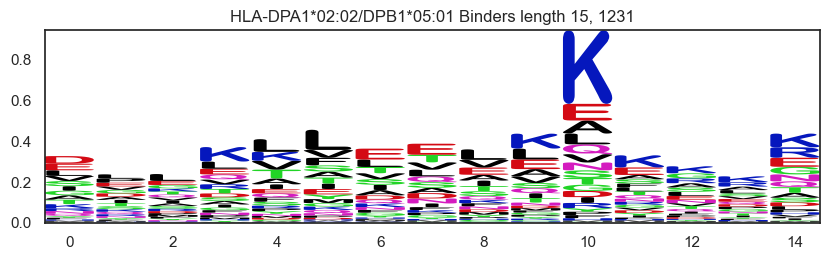

In [55]:
target_length = 15
peptides = per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]
make_logo_for_data(peptides, f"{ target_allele} Binders length {target_length}")

# Transform data

In [56]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test


if check_peptides:
    transform_dicts=None

per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
    combination_size=combination_size,
    selected_alelles=ALLELES,
    total_splits=TOTAL_SPLITS,
    list_of_transform_dicts=None,position_component=params['position_component']
)
OLD_ALLELES = ALLELES
NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
ALLELES = NEW_ALLELES

HLA-DPA1*02:02/DPB1*05:01
Length 9: HLA-DPA1*02:02/DPB1*05:01 - 12 
Length 10: HLA-DPA1*02:02/DPB1*05:01 - 53 
Length 11: HLA-DPA1*02:02/DPB1*05:01 - 204 
Length 12: HLA-DPA1*02:02/DPB1*05:01 - 420 
Length 13: HLA-DPA1*02:02/DPB1*05:01 - 790 
Length 14: HLA-DPA1*02:02/DPB1*05:01 - 1241 
Length 15: HLA-DPA1*02:02/DPB1*05:01 - 1231 
Length 16: HLA-DPA1*02:02/DPB1*05:01 - 927 
Length 17: HLA-DPA1*02:02/DPB1*05:01 - 628 
Length 18: HLA-DPA1*02:02/DPB1*05:01 - 403 
Length 19: HLA-DPA1*02:02/DPB1*05:01 - 232 
Length 20: HLA-DPA1*02:02/DPB1*05:01 - 121 
Length 21: HLA-DPA1*02:02/DPB1*05:01 - 72 
Length 22: HLA-DPA1*02:02/DPB1*05:01 - 36 
Length 23: HLA-DPA1*02:02/DPB1*05:01 - 25 
Length 24: HLA-DPA1*02:02/DPB1*05:01 - 9 
Length 25: HLA-DPA1*02:02/DPB1*05:01 - 10 
Length 26: HLA-DPA1*02:02/DPB1*05:01 - 6 


In [57]:
per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][9][0]

'YPLHTYPKE'

## 2.2 Calculate counts of initial data (will be used to calculate weights further)

In [58]:
from data_reading_methods import extract_count_df, calculate_weights_based_on_length_counts

count_df_train = extract_count_df(per_allele_per_kfold_per_length_binders_train_old,
                                  selected_alleles=OLD_ALLELES,
                                  total_splits=TOTAL_SPLITS)
count_df_test = extract_count_df(per_allele_per_kfold_per_length_binders_test_old,
                                 selected_alleles=OLD_ALLELES,
                                 total_splits=TOTAL_SPLITS)


In [59]:
count_df_train.index.levels

FrozenList([['HLA-DPA1*02:02/DPB1*05:01'], [0, 1, 2, 3, 4], [9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26]])

## 2.3 Weights for data based on counts

In [60]:
sub_count_df_train = count_df_train.loc[(count_df_train.index.get_level_values('split') == 0) &
                                        (count_df_train.index.get_level_values('allele').isin(ALLELES)) &
                                        (count_df_train.index.get_level_values('length').isin(TARGET_LENGTHS))]

In [61]:
sub_count_df_train['cnt'].sum()

5640

In [62]:
per_allele_per_kfold_per_length_weights = calculate_weights_based_on_length_counts(count_df_train,
                                                                                   selected_alleles=ALLELES,
                                                                                   total_splits=TOTAL_SPLITS,
                                                                                   selected_lengths=TARGET_LENGTHS,
                                                                                   use_weights=USE_WEIGHTS)

Total data length for split 0 is 5640
Weights for lentgh 12 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 13 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 14 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 15 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 16 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 17 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 18 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Devide by 1
Combination HLA-DPA1*02:02/DPB1*05:01, split 0: {12: array([1.]), 13: array([1.]), 14: array([1.]), 15: array([1.]), 16: array([1.]), 17: array([1.]), 18: array([1.])}
Total data length for split 1 is 5640
Weights for lentgh 12 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 13 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 14 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 15 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 16 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 17 are {'HLA-DPA1

## Transform to properties

# 2. Train HMMS
## 2.1 Code for HMM
### 2.1.1 Training code

In [63]:
from hmm_logic_methods import train_model,  train_model_batched, save_model, add_more_states_and_reset_transitions, init_grouped_structure_model_joiners_and_cycles_here



## 2.2 Train
### 2.2.1 Define treshold

In [64]:
stop_threshold = 0
cutoff = 0.00005
per_symbol_portion = -5
for target_length in TARGET_LENGTHS:
    target_length_for_training = target_length
    train_size = len(per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length])
    ## Stop threshold Hardcoded here
    stop_threshold +=  abs(cutoff * train_size * per_symbol_portion  * target_length_for_training)
stop_threshold = stop_threshold / len(TARGET_LENGTHS)

params['stop_threshold'] = stop_threshold

stop_threshold

2.9968214285714287

In [65]:
sum([item for item in per_allele_per_kfold_per_length_weights[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])

2821.0

In [66]:
list(np.arange(1,6))

[1, 2, 3, 4, 5]

### 2.2.2 Prepare  initial grouped structure models

In [67]:
prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
    states_per_group=int(params['states_per_group']),
    number_of_groups=params['groups'],
    CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'],
    freeze_distr=params['freeze_distr'],
    initial_params=initial_params,
    start_cycle=params['start_cycle'],
    end_cycle=params['end_cycle'],
    self_cycles=params['self_cycle'],
    discrete_distribution=check_peptides,
    equal_probs_for_cycle=params['equal_probs_for_cycle'],
    tie_cycle_states=params['tie_cycle_states'],
    anchor_max_components=params['anchor_top_aas'],
    anchor_states=params['anchor_states'],
    model_complexity=params['model_complexity'],
    anchor_default_pseudocount= params['anchor_default_pseudocount'],
    tie_anchor_states=params['tie_anchor_states'],
                    intermediate_cycles=params['intermediate_cycles'],
                    equal_probs_for_intermediate_cycle=params['equal_probs_for_intermediate_cycle'],
                    tie_intermediate_cycles=params['tie_intermediate_cycles'],
                    freeze_int_cycle_distr=params['freeze_int_cycle_distr'],
    position_component=params['position_component'],
    cycle_chain=params['cycle_chain']

)

start cycles added 10
end cycles added 20
states will be groups:14 + joiners:4 + start/end cycles:20 + int_cycles:0
One more time number of 'cycle' states 10 10
For example start cycle states [18, 19, 20, 21, 22, 23, 24, 25, 26, 27]


In [68]:
from itertools import islice

In [69]:
prepared_model.dense_transition_matrix().shape

(40, 40)

In [70]:
with open('model.png', 'w+') as f:
    prepared_model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

In [71]:
from hmm_visualization_methods import *
plot_distributions_for_states(prepared_model,"test/", horizontal=False, discrete=check_peptides, initial_params=initial_params)

In [72]:

make_pyviz_graph(prepared_model, "test/", precision=3)

Converting graph for model (grouped_model) (Delete zero edges)


<class 'pyvis.network.Network'> |N|=40 |E|=92

In [73]:
peptide = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][18][0]

In [74]:
prepared_model.log_probability(peptide)

-56.22651218054017

In [75]:
peptide

'NGSQFFITTVKTAWLDGK'

In [76]:

per_length_data = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0]
target_lengths = per_length_data.keys()
binders_array = np.array([per_length_data[target_length][i] for target_length in target_lengths
                          for i in range(len(per_length_data[target_length]))], dtype=object)

In [77]:
sample_X = np.array([[char for char in item] for item in binders_array], dtype=object)

In [78]:
sample_X[0]

['Y', 'P', 'L', 'H', 'T', 'Y', 'P', 'K', 'E']

In [79]:
isinstance(sample_X, pomegranate.io.BaseGenerator)

False

In [80]:
from pomegranate.io import SequenceGenerator, BatchedDataGenerator
sg = SequenceGenerator(binders_array)

for t in sg.batches():
    print(t)
    break

In [81]:
cnt = 0
for t in sg.batches():
   # print(t)
    cnt += 1
    #break

In [82]:
sg = BatchedDataGenerator(sample_X, batch_size=10, batches_per_epoch=3)

In [83]:
# cnt = 0
for t in sg.batches():
   # print(t)
    cnt += 1
 #   print(t)
    #break

In [84]:
t

(array([list(['A', 'V', 'N', 'A', 'H', 'S', 'N', 'I', 'L', 'K']),
        list(['F', 'V', 'F', 'A', 'V', 'K', 'N', 'E', 'N', 'R']),
        list(['Y', 'S', 'T', 'L', 'L', 'E', 'S', 'E', 'K', 'N']),
        list(['N', 'G', 'E', 'R', 'I', 'E', 'K', 'V', 'E', 'H']),
        list(['K', 'E', 'S', 'T', 'L', 'H', 'L', 'V', 'L', 'R']),
        list(['L', 'E', 'N', 'G', 'K', 'E', 'T', 'L', 'Q', 'R']),
        list(['Y', 'T', 'E', 'F', 'T', 'P', 'T', 'E', 'K', 'D']),
        list(['K', 'Q', 'E', 'I', 'L', 'A', 'A', 'L', 'E', 'K']),
        list(['A', 'S', 'T', 'S', 'T', 'T', 'I', 'R', 'S', 'H']),
        list(['L', 'E', 'N', 'G', 'K', 'D', 'K', 'L', 'E', 'R'])],
       dtype=object),
 array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]))

In [85]:
t[0]

array([list(['A', 'V', 'N', 'A', 'H', 'S', 'N', 'I', 'L', 'K']),
       list(['F', 'V', 'F', 'A', 'V', 'K', 'N', 'E', 'N', 'R']),
       list(['Y', 'S', 'T', 'L', 'L', 'E', 'S', 'E', 'K', 'N']),
       list(['N', 'G', 'E', 'R', 'I', 'E', 'K', 'V', 'E', 'H']),
       list(['K', 'E', 'S', 'T', 'L', 'H', 'L', 'V', 'L', 'R']),
       list(['L', 'E', 'N', 'G', 'K', 'E', 'T', 'L', 'Q', 'R']),
       list(['Y', 'T', 'E', 'F', 'T', 'P', 'T', 'E', 'K', 'D']),
       list(['K', 'Q', 'E', 'I', 'L', 'A', 'A', 'L', 'E', 'K']),
       list(['A', 'S', 'T', 'S', 'T', 'T', 'I', 'R', 'S', 'H']),
       list(['L', 'E', 'N', 'G', 'K', 'D', 'K', 'L', 'E', 'R'])],
      dtype=object)

## Prepare models

In [86]:
per_allele_per_run_per_split_prepared_models = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_').replace('/', '_')
    per_allele_per_run_per_split_prepared_models[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
        for split_num in range(TOTAL_SPLITS):
            # prepared_model  = init_grouped_structure_model(states_per_group=int(params['st']/params['groups']), number_of_groups=params['groups'])
            prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
                states_per_group=int(params['states_per_group']),
                number_of_groups=params['groups'],
                CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'],
                freeze_distr=params['freeze_distr'],
                initial_params=initial_params,
                start_cycle=params['start_cycle'],
                end_cycle=params['end_cycle'],
                self_cycles=params['self_cycle'],
                discrete_distribution=check_peptides,
                equal_probs_for_cycle=params['equal_probs_for_cycle'],
                tie_cycle_states=params['tie_cycle_states'],
                 model_complexity=params['model_complexity'],
                     anchor_default_pseudocount= params['anchor_default_pseudocount'] ,
             anchor_max_components=params['anchor_top_aas'],
                anchor_states=params['anchor_states'],
                   tie_anchor_states=params['tie_anchor_states'],
                    intermediate_cycles=params['intermediate_cycles'],
                    equal_probs_for_intermediate_cycle=params['equal_probs_for_intermediate_cycle'],
                    tie_intermediate_cycles=params['tie_intermediate_cycles'],
                    freeze_int_cycle_distr=params['freeze_int_cycle_distr'],
                position_component=params['position_component'],
    cycle_chain=params['cycle_chain'],
                

            )



            prepared_model.name = f'{run_num}_run-{lengths_string}-{params_string}_model-{target_allele_name}-{split_num}'
            per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = prepared_model

start cycles added 10
end cycles added 20
states will be groups:14 + joiners:4 + start/end cycles:20 + int_cycles:0
One more time number of 'cycle' states 10 10
For example start cycle states [18, 19, 20, 21, 22, 23, 24, 25, 26, 27]
start cycles added 10
end cycles added 20
states will be groups:14 + joiners:4 + start/end cycles:20 + int_cycles:0
One more time number of 'cycle' states 10 10
For example start cycle states [18, 19, 20, 21, 22, 23, 24, 25, 26, 27]
start cycles added 10
end cycles added 20
states will be groups:14 + joiners:4 + start/end cycles:20 + int_cycles:0
One more time number of 'cycle' states 10 10
For example start cycle states [18, 19, 20, 21, 22, 23, 24, 25, 26, 27]
start cycles added 10
end cycles added 20
states will be groups:14 + joiners:4 + start/end cycles:20 + int_cycles:0
One more time number of 'cycle' states 10 10
For example start cycle states [18, 19, 20, 21, 22, 23, 24, 25, 26, 27]
start cycles added 10
end cycles added 20
states will be groups:14 +

In [87]:
# cycle_state = prepared_model.states[27]
# start = prepared_model.states[29]
# prepared_model.graph.edges()[cycle_state, cycle_state]

## Do training

In [88]:
NUM_RUNS

2

In [89]:
params['multiple_check_input']

False

In [ ]:
%%time
TOTAL_SPLITS = 1
per_name_models = dict()
per_allele_per_run_per_split_new_histories = dict()
for allele_name in ALLELES:
    per_allele_per_run_per_split_new_histories[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        print(f"run {run_num}")
        per_kfold_per_length_data = per_allele_per_kfold_per_length_binders_train[allele_name]
        per_kfold_per_length_weights = per_allele_per_kfold_per_length_weights[allele_name]
        


        models, histories = train_model_batched(allele_name=allele_name,
                                        per_kfold_per_length_data=per_kfold_per_length_data,
                                        per_kfold_per_length_weights_for_data=per_kfold_per_length_weights,
                                        target_lengths=TARGET_LENGTHS,
                                        multiple_check_input=params['multiple_check_input'],
                                        algorithm=params['alg'],
                                        verbose=params['verbose'],
                                        per_kfold_per_length_test_data=per_allele_per_kfold_per_length_binders_test[allele_name],
                                        stop_threshold=params['stop_threshold'],
                                        min_iterations= params['min_iters'],
                                        max_iterations=params['max_iters'],
                                        prepared_models=per_allele_per_run_per_split_prepared_models[allele_name][run_num],
                                        emission_pseudocount=params['emission_pseudocount'],
                                        transition_pseudocount=params['transition_pseudocount'],
                                        edge_inertia=params['edge_inertia'],
                                        distribution_inertia=params['distribution_inertia'],
                                        lr_decay=params['lr_decay'],
                                        use_pseudocount=params['use_pseudocount'],
                                        minibatch_training=False,
                                        batches_per_epoch=params['batches_per_epoch'],
                                          batch_size=params['batch_size'],
                                       n_jobs=1)

        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = models
        per_allele_per_run_per_split_new_histories[allele_name][run_num] = histories
        # per_allele_per_run_per_split_models[allele_name][run_num] = models
        for split_num, model in models.items():
            per_name_models[model.name] = model
        # save models
        for split_num, model in models.items():
            history = histories[split_num]
            save_model(TARGET_PATH_TO_RESULTS, model,history)

In [ ]:
%%time
TOTAL_SPLITS = 1
per_name_models = dict()
per_allele_per_run_per_split_new_histories = dict()
for allele_name in ALLELES:
    per_allele_per_run_per_split_new_histories[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        print(f"run {run_num}")
        per_kfold_per_length_data = per_allele_per_kfold_per_length_binders_train[allele_name]
        per_kfold_per_length_weights = per_allele_per_kfold_per_length_weights[allele_name]
        


        models, histories = train_model(allele_name=allele_name,
                                        per_kfold_per_length_data=per_kfold_per_length_data,
                                        per_kfold_per_length_weights_for_data=per_kfold_per_length_weights,
                                        target_lengths=TARGET_LENGTHS,
                                        multiple_check_input=params['multiple_check_input'],
                                        algorithm=params['alg'],
                                        verbose=params['verbose'],
                                        per_kfold_per_length_test_data=per_allele_per_kfold_per_length_binders_test[allele_name],
                                        stop_threshold=params['stop_threshold'],
                                        min_iterations= params['min_iters'],
                                        max_iterations=params['max_iters'],
                                        prepared_models=per_allele_per_run_per_split_prepared_models[allele_name][run_num],
                                        emission_pseudocount=params['emission_pseudocount'],
                                        transition_pseudocount=params['transition_pseudocount'],
                                        edge_inertia=params['edge_inertia'],
                                        distribution_inertia=params['distribution_inertia'],
                                        lr_decay=params['lr_decay'],
                                        use_pseudocount=params['use_pseudocount'],
                                        minibatch_training=params['minibatch_training'],
                                        batches_per_epoch=params['batches_per_epoch'],
                                          batch_size=params['batch_size'],
                                       n_jobs=1)

        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = models
        per_allele_per_run_per_split_new_histories[allele_name][run_num] = histories
        # per_allele_per_run_per_split_models[allele_name][run_num] = models
        for split_num, model in models.items():
            per_name_models[model.name] = model
        # save models
        for split_num, model in models.items():
            history = histories[split_num]
            save_model(TARGET_PATH_TO_RESULTS, model,history)



In [92]:
prepared_model.discrete

True

In [95]:

# Sort by score
per_name_new_models = dict()
per_name_histories = dict()
for split_num in range(TOTAL_SPLITS):
    for allele_name in ALLELES:
        df = pd.DataFrame({"model": np.arange(NUM_RUNS), 
                          "log_probability": [per_allele_per_run_per_split_new_histories[allele_name][i][split_num].log_probabilities[-1]
                                             for i in range(NUM_RUNS)],
                         # "test_log_probability":  [per_allele_per_run_per_split_new_histories[allele_name][i][split_num].test_log_probability[-1]
                          #                   for i in range(NUM_RUNS)]
                          })
        df = df.sort_values(by='log_probability', ascending = False).reset_index(drop=True)
        for new_index, model_run_num in zip(np.arange(len(df)), df.model):
            original_model =  per_allele_per_run_per_split_prepared_models[allele_name][model_run_num][split_num]
            original_history = per_allele_per_run_per_split_new_histories[allele_name][model_run_num][split_num]
            original_model_name = original_model.name
            rest_part = original_model_name.split("_", 1)[1]
            new_name = f"{new_index}_{rest_part}"
            original_model.name = new_name
            per_name_new_models[new_name] = original_model
            per_name_histories[new_name] = original_history
per_name_models = per_name_new_models
        
        

In [96]:
for name, model in per_name_models.items():
    history = per_name_histories[name]
    save_model(TARGET_PATH_TO_RESULTS, model,history)
    

In [97]:
per_name_models = per_name_new_models

In [98]:
from hmm_visualization_methods import *

<AxesSubplot: >

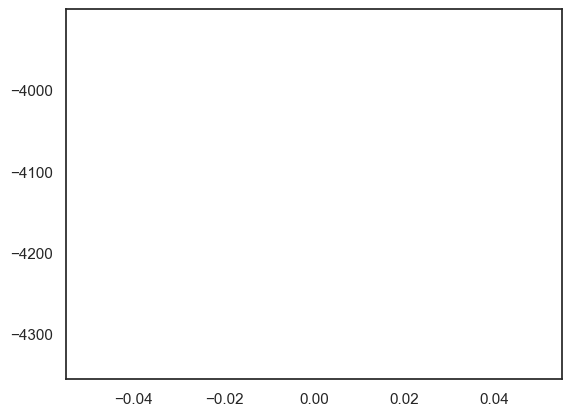

In [99]:
sns.lineplot(
    per_name_histories[
        list(per_name_histories.keys())[0]
    ].log_probabilities)

In [100]:
%%time

for i, model in enumerate(per_name_models.values()):
    print(i)
    # with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png", 'w+') as f:
    #     model.plot(file=f, crop_zero=False)
    with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph_cropped.png", 'w+') as f:
        model.plot(file=f, crop_zero=True)

0
1
CPU times: total: 31.2 ms
Wall time: 592 ms


In [101]:
from importlib import reload  # Python 3.4+
import hmm_visualization_methods
from hmm_visualization_methods import *
hmm_visualization_methods= reload(hmm_visualization_methods)
from hmm_visualization_methods import *

In [102]:
%%time

for i, model in enumerate(per_name_models.values()):
    plot_distributions_for_states(model,TARGET_PATH_TO_RESULTS, horizontal=False, discrete=check_peptides, initial_params=initial_params)
    print(i)

0
1
CPU times: total: 10.5 s
Wall time: 10.7 s


In [103]:
from hmm_visualization_methods import *


per_name_pyviz = dict()
for name, model in per_name_models.items():
    per_name_pyviz[name] = make_pyviz_graph(model, TARGET_PATH_TO_RESULTS, precision=3)

Converting graph for model (0_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0) (Delete zero edges)
Converting graph for model (1_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0) (Delete zero edges)


## See how viterbi steps look like

In [130]:
peptide = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][16][0]

In [131]:
per_length_data =  per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0]
binders_array = np.array([per_length_data[target_length][i] for target_length in [16]
                          for i in range(len(per_length_data[target_length]))], dtype=object)

In [132]:
binders_array = binders_array[0:2]

In [107]:
binders_array = np.array(['AAAAAAAAAAAAAAAA', 'EEEEEEEEEEEEEEEE'])

In [138]:
prob, path, e, v, tracex, tracey = prepared_model.viterbi_with_track(binders_array[1])

38


In [141]:
binders_array[1]

'GSHKIQSDFIYFRKGP'

In [142]:
[item[1].name for item in path]

['grouped_model-start',
 's026',
 's027',
 's015',
 's000',
 's003',
 's005',
 's006',
 's008',
 's010',
 's013',
 's016',
 's028',
 's029',
 's030',
 's031',
 's032',
 'grouped_model-end']

In [111]:
e_df = pd.DataFrame(e)
v_df = pd.DataFrame(v)
tracex_df = pd.DataFrame(tracex)
tracey_df= pd.DataFrame(tracey)


In [112]:
peptide

'ACESVIQTACKHIRSG'

In [113]:
np.log(prepared_model.states[0].distribution.parameters[0][peptide[5]])

-2.8546503342604708

In [114]:
prepared_model.states[0].distribution.parameters[0]

{'A': 0.04456133592761405,
 'C': 0.031227279851501737,
 'D': 0.06088261976661721,
 'E': 0.051801381931068924,
 'F': 0.06853943407709409,
 'G': 0.03174387552610421,
 'H': 0.07836887504413173,
 'I': 0.05757594993862037,
 'K': 0.07189659690161244,
 'L': 0.07447022863248891,
 'M': 0.034422902258321904,
 'N': 0.02961662049942185,
 'P': 0.03328078174258184,
 'Q': 0.024311377291213736,
 'R': 0.05715057687671614,
 'S': 0.07466223589035555,
 'T': 0.07915404797731466,
 'V': 0.05169657970268846,
 'W': 0.012390268706023723,
 'Y': 0.032247031458508206}

In [115]:
np.log(prepared_model.dense_transition_matrix()[29, 25]) + e_df.loc[1,25]

C:\Users\denkl\AppData\Local\Temp\ipykernel_22932\105886122.py:1: RuntimeWarning: divide by zero encountered in log
  np.log(prepared_model.dense_transition_matrix()[29, 25]) + e_df.loc[1,25]


-inf

In [116]:
e_df

,0,1,2,3,4,5,6,7,8,9,...,28,29,30,31,32,33,34,35,36,37
0,-3.110889,-3.101964,-4.134984,-3.227500,-4.787560,-3.596155,-2.329216,-2.696077,-2.719960,-5.068004,...,-2.980060,-5.115034,-4.944330,-4.611126,-3.498878,-2.799100,-3.244323,-4.100133,-2.853573,-6.997720
1,-3.466463,-2.961698,-2.793964,-3.276572,-3.061380,-4.720819,-2.728458,-3.854538,-2.504670,-2.361234,...,-2.614579,-2.475680,-2.600637,-2.728499,-2.506070,-2.677622,-4.190007,-2.789601,-2.614496,-2.818940
2,-2.960338,-4.475183,-3.897167,-3.048061,-2.650269,-2.529948,-2.622555,-2.514138,-3.709392,-5.762573,...,-3.242930,-3.169843,-2.639717,-2.815328,-3.961326,-3.133491,-3.789447,-2.786431,-2.787486,-2.509724
3,-2.594781,-2.489521,-4.319573,-2.486377,-2.964620,-3.471054,-2.578719,-7.069961,-3.003278,-2.973274,...,-3.767466,-4.168169,-4.687171,-2.524578,-4.477279,-2.774397,-3.933798,-2.795080,-2.630238,-3.077855
4,-2.962364,-2.632639,-2.640850,-2.443825,-3.260748,-2.757684,-2.662060,-2.707006,-2.873122,-2.903057,...,-3.127602,-3.315484,-2.742518,-4.077442,-2.331064,-5.575533,-2.615410,-2.874885,-2.562129,-3.055153
5,-2.854650,-2.462682,-2.933982,-2.460927,-3.224976,-3.778669,-3.092305,-3.165329,-4.339330,-2.509037,...,-2.466691,-2.504382,-2.630773,-2.739095,-2.628374,-2.241299,-3.064103,-2.759364,-3.156752,-3.153887
6,-3.716811,-3.055808,-2.832677,-3.385618,-3.299217,-2.459156,-6.853153,-4.482708,-2.660590,-2.385312,...,-2.444146,-3.777009,-2.707598,-3.277997,-2.682832,-6.185035,-2.621104,-2.622681,-2.525335,-2.548022
7,-2.536359,-2.457952,-3.096542,-3.221080,-2.385401,-2.583271,-3.320098,-5.434509,-2.821532,-2.929910,...,-3.250224,-3.306770,-5.071548,-2.666834,-3.219067,-3.656238,-2.682327,-2.591021,-3.206255,-3.022021
8,-3.110889,-3.101964,-4.134984,-3.227500,-4.787560,-3.596155,-2.329216,-2.696077,-2.719960,-5.068004,...,-2.980060,-5.115034,-4.944330,-4.611126,-3.498878,-2.799100,-3.244323,-4.100133,-2.853573,-6.997720
9,-3.466463,-2.961698,-2.793964,-3.276572,-3.061380,-4.720819,-2.728458,-3.854538,-2.504670,-2.361234,...,-2.614579,-2.475680,-2.600637,-2.728499,-2.506070,-2.677622,-4.190007,-2.789601,-2.614496,-2.818940


<AxesSubplot: >

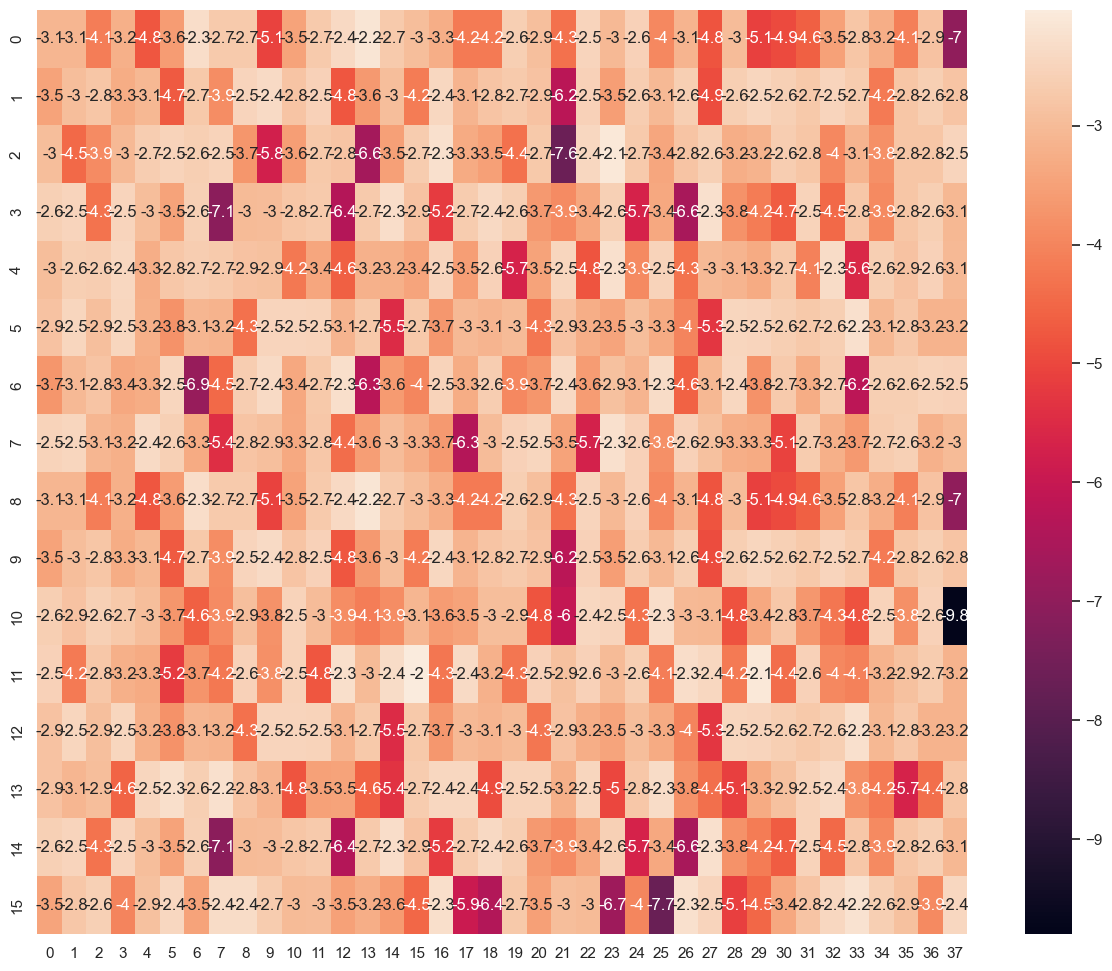

In [117]:
plt.figure(figsize=(15,12))
sns.heatmap(e_df, annot=True)

In [118]:
np.log(0.41)

-0.8915981192837836

In [119]:
prepared_model.start_index

38

In [120]:
v_df

,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
0,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,0.0,-inf
1,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
2,-9.364552,-8.859787,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
3,-12.918738,-14.938348,-13.855566,-13.006460,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
4,-17.199880,-16.506871,-18.336923,-16.503727,-17.069693,-17.576127,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
5,-18.312603,-17.982879,-20.243189,-20.049309,-20.863087,-20.360023,-20.830366,-20.875312,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
6,-20.690429,-20.298460,-22.015473,-21.542418,-24.372896,-24.926590,-24.550940,-24.623964,-26.268308,-24.438015,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
7,-25.113884,-24.844849,-24.229750,-24.782690,-25.940248,-25.100186,-32.324662,-29.954217,-28.197217,-28.034864,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
8,-28.479821,-28.670448,-28.977845,-28.549442,-27.713763,-27.911633,-29.518896,-31.633307,-31.955008,-32.225740,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
9,-32.879949,-32.680396,-33.713417,-32.805933,-33.797805,-32.408530,-31.141592,-31.508452,-33.337469,-35.685513,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-39.083757


<AxesSubplot: >

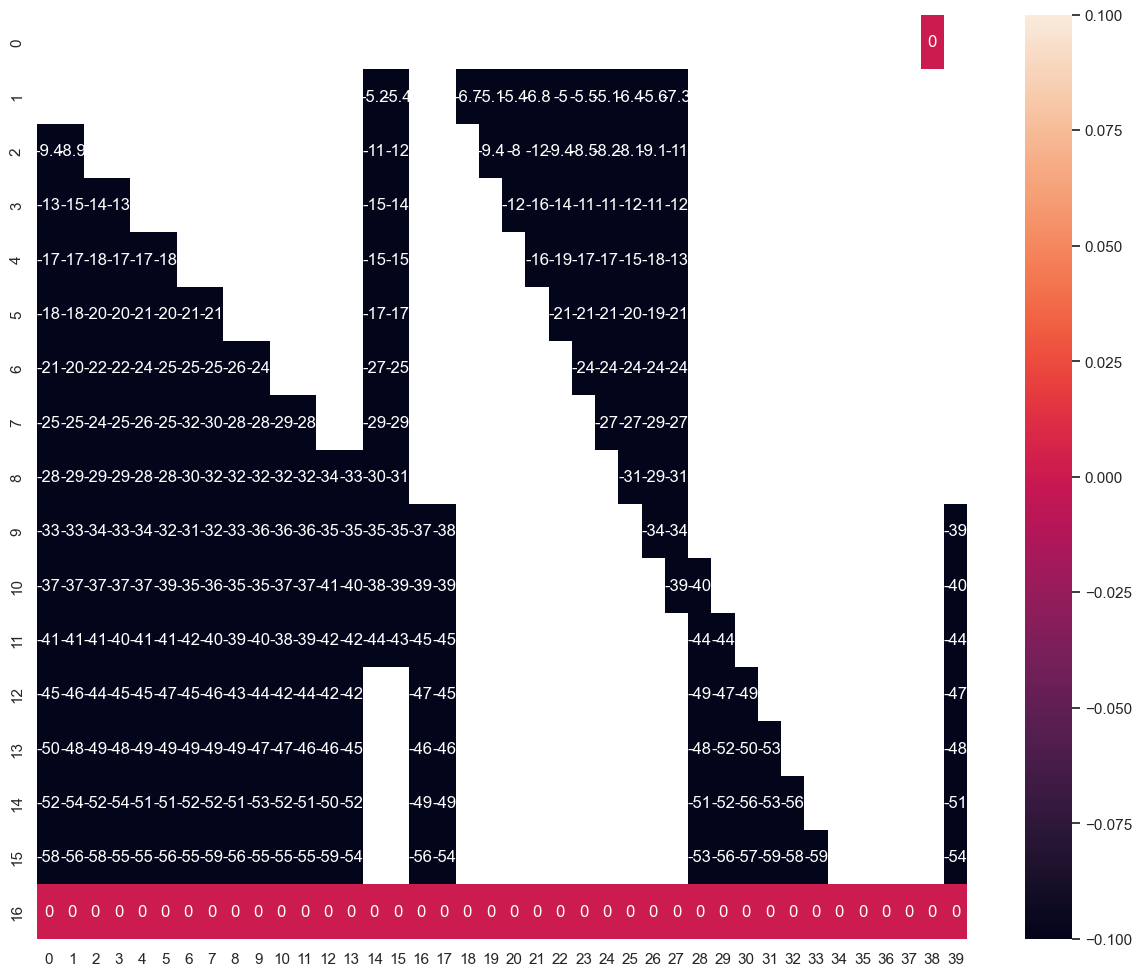

In [121]:
plt.figure(figsize=(15,12))
sns.heatmap(v_df, annot=True)

In [122]:
v_df1 = v_df.divide(v_df.index, axis="rows")

<AxesSubplot: >

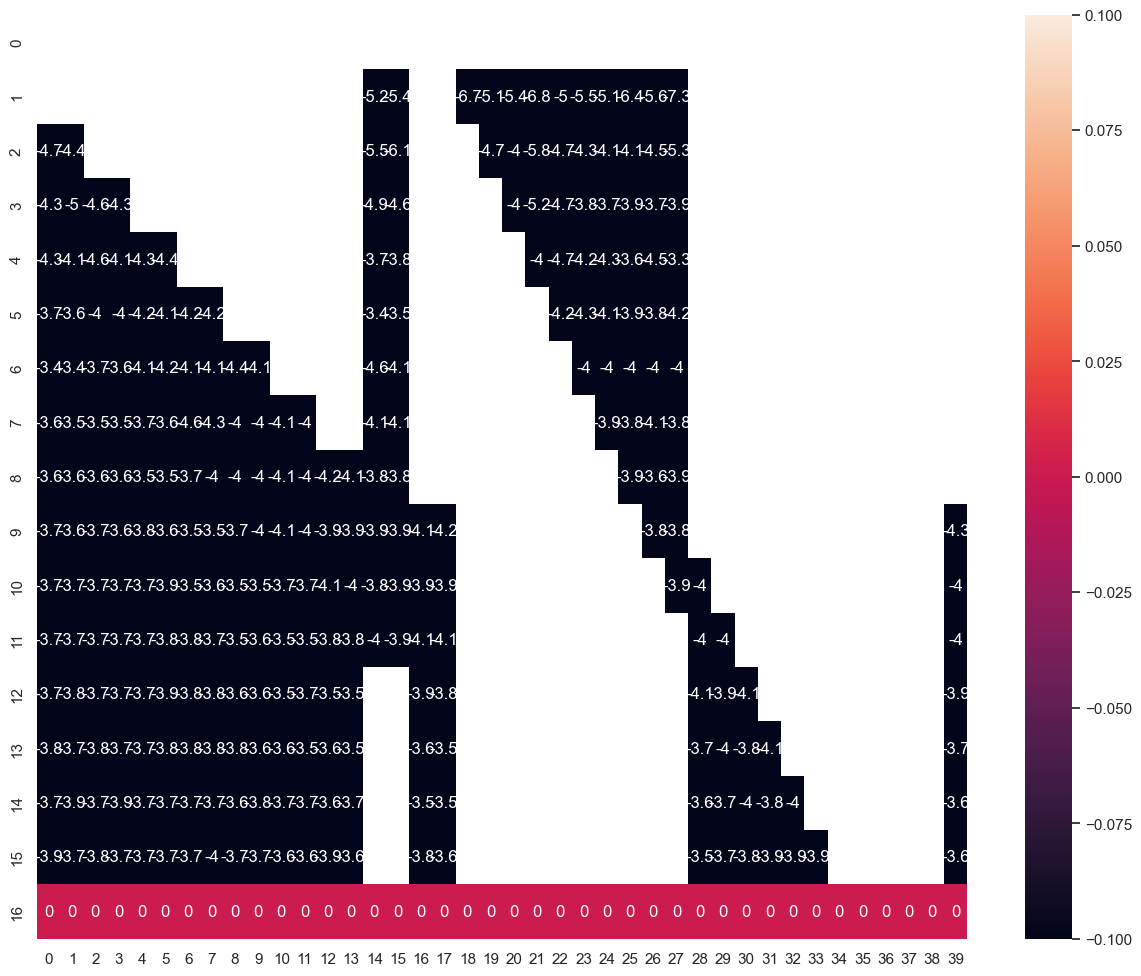

In [123]:
plt.figure(figsize=(15,12))
sns.heatmap(v_df1, annot=True)

<AxesSubplot: >

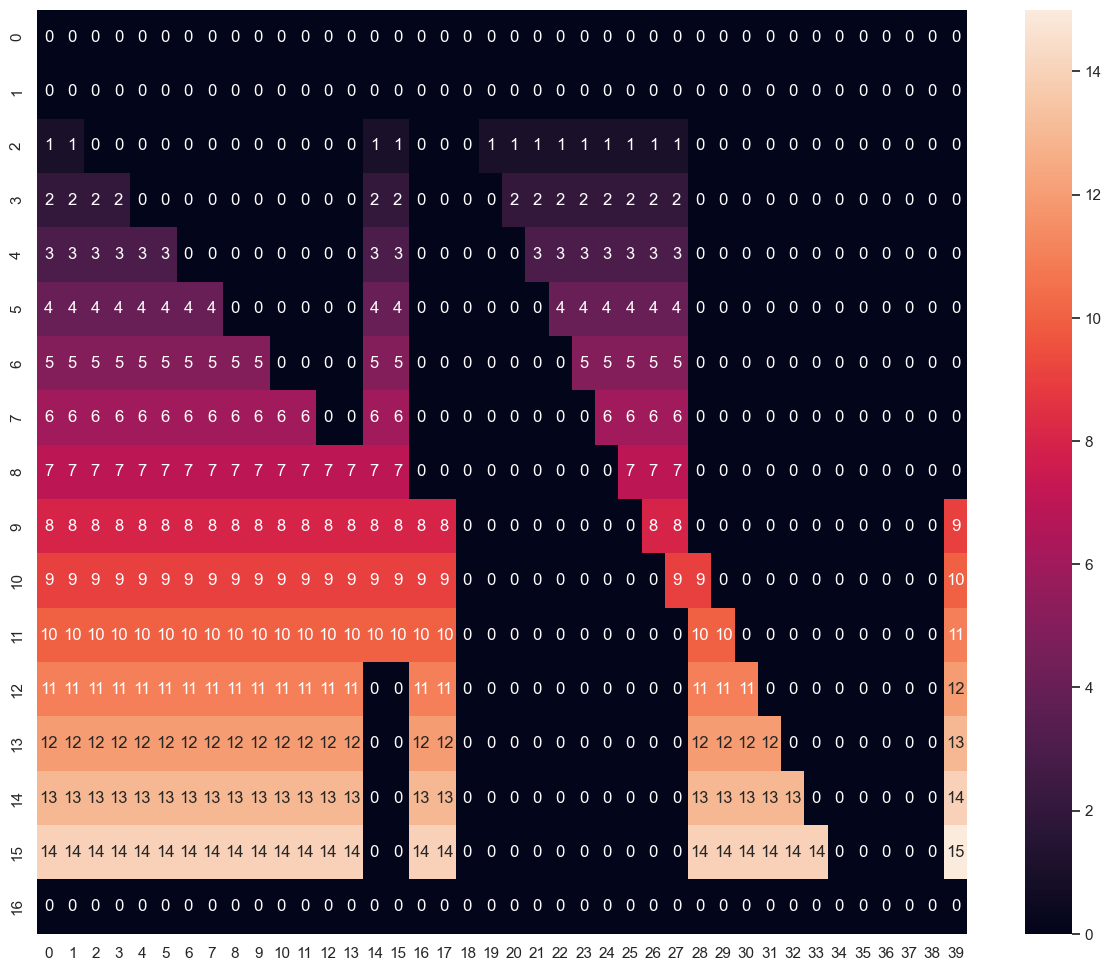

In [124]:
plt.figure(figsize=(15,12))
sns.heatmap(tracex_df, annot=True)

<AxesSubplot: >

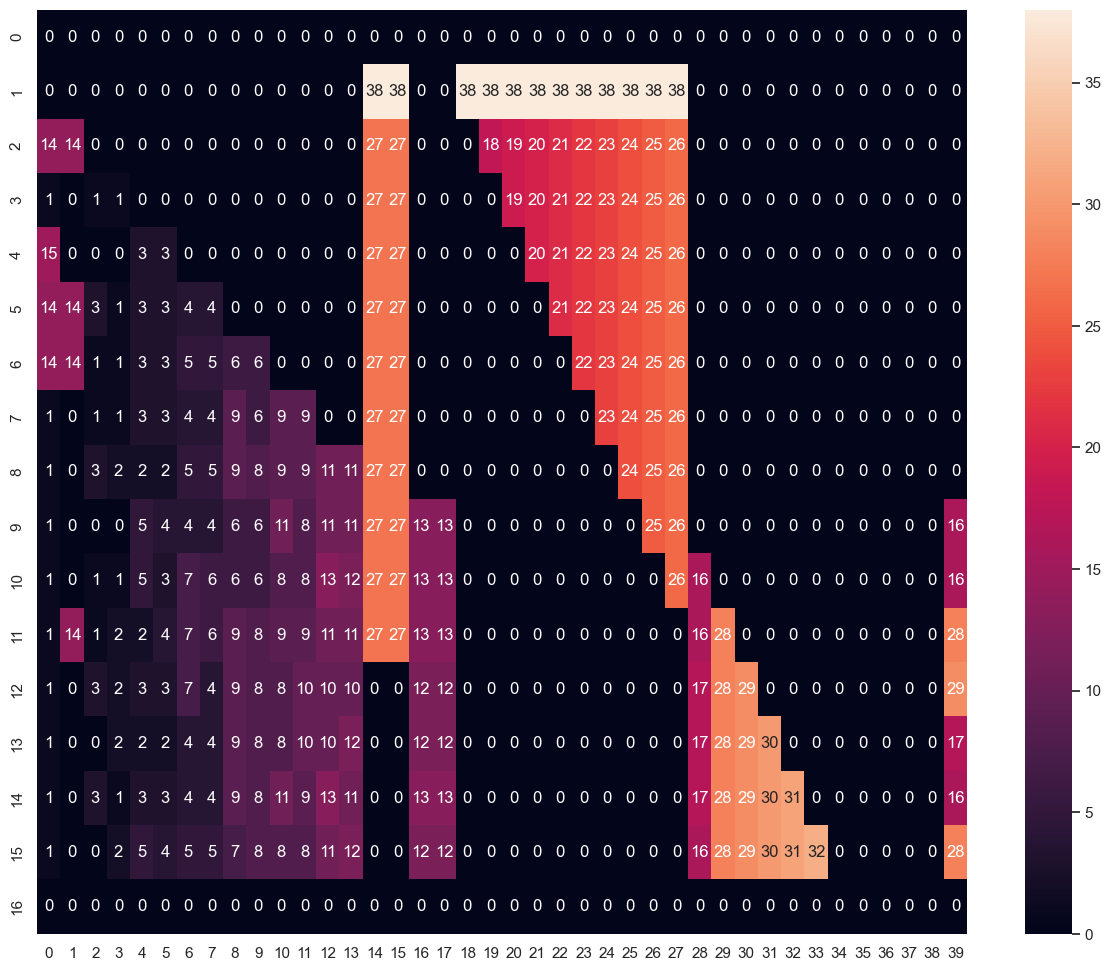

In [125]:
plt.figure(figsize=(15,12))
sns.heatmap(tracey_df, annot=True)

In [126]:
pd.DataFrame(v)

,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
0,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,0.0,-inf
1,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
2,-9.364552,-8.859787,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
3,-12.918738,-14.938348,-13.855566,-13.006460,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
4,-17.199880,-16.506871,-18.336923,-16.503727,-17.069693,-17.576127,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
5,-18.312603,-17.982879,-20.243189,-20.049309,-20.863087,-20.360023,-20.830366,-20.875312,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
6,-20.690429,-20.298460,-22.015473,-21.542418,-24.372896,-24.926590,-24.550940,-24.623964,-26.268308,-24.438015,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
7,-25.113884,-24.844849,-24.229750,-24.782690,-25.940248,-25.100186,-32.324662,-29.954217,-28.197217,-28.034864,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
8,-28.479821,-28.670448,-28.977845,-28.549442,-27.713763,-27.911633,-29.518896,-31.633307,-31.955008,-32.225740,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf
9,-32.879949,-32.680396,-33.713417,-32.805933,-33.797805,-32.408530,-31.141592,-31.508452,-33.337469,-35.685513,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-39.083757


In [127]:
pd.DataFrame(tracex)

,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2.0,2.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,3.0,3.0,3.0,3.0,3.0,3.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,5.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,6.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,7.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,8.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0


In [128]:
pd.DataFrame(tracey)

,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,14.0,14.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,15.0,0.0,0.0,0.0,3.0,3.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,14.0,14.0,3.0,1.0,3.0,3.0,4.0,4.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,14.0,14.0,1.0,1.0,3.0,3.0,5.0,5.0,6.0,6.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,1.0,0.0,1.0,1.0,3.0,3.0,4.0,4.0,9.0,6.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,1.0,0.0,3.0,2.0,2.0,2.0,5.0,5.0,9.0,8.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,1.0,0.0,0.0,0.0,5.0,4.0,4.0,4.0,6.0,6.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,16.0


In [ ]:
# allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])
# ten_mer = allele_peptides[12]
# print(ten_mer, len(ten_mer))
#prob, path = model.viterbi(ten_mer)
#print([item[0] for item in path])
# sixteen_mer = peptide_properties[8900]
# print(sixteen_mer, len(sixteen_mer))

In [28]:
#pd.DataFrame(model.forward(sixteen_mer))

In [29]:
#pd.DataFrame(model.forward_backward(sixteen_mer)[1])

In [30]:
#pd.DataFrame(model.forward_backward(ten_mer)[1])

In [31]:
#ten_mer

In [32]:
#state_sums = [sum(state.distribution.parameters[0].values()) for state in model.states[:-2]]
# assert np.isclose(sum(state_sums), len(state_sums))

## Training steps

In [47]:

params['st'] = 21
params['multiple_check_input'] = True
params['alg'] = algorithm
params['min_iters'] = 30
params['max_iters'] = 65
params['stop_threshold'] = stop_threshold
params['emission_pseudocount'] = 1
params['transition_pseudocount'] = 1
params['verbose'] = True
params['lr_decay'] = 0.9
params['edge_inertia'] = 0.4
params['distribution_inertia'] = 0.4
params['groups'] = 7
params['states_per_group'] = 3
params['model_complexity'] = 3
params['use_pseudocount'] = True

# Class 1 params
params['self_cycle'] = False
params['start_cycle'] = True
params['end_cycle'] = True
params['equal_probs_for_cycle'] = False

params['freeze_distr'] = False # wether to freeze start and end cycle distributions
params['tie_cycle_states'] = False
params['cycle_pseudocount'] = 300

In [48]:
allele_name = ALLELES[0]
per_kfold_per_length_train_data = per_allele_per_kfold_per_length_binders_train[allele_name]
per_kfold_per_length_test_data = per_allele_per_kfold_per_length_binders_test[allele_name]
per_kfold_per_length_weights_for_data = per_allele_per_kfold_per_length_weights[allele_name]
split_num = 0
target_lengths = TARGET_LENGTHS
per_length_current_weights = per_kfold_per_length_weights_for_data[split_num]
per_length_data = per_kfold_per_length_train_data[split_num]

per_length_test_data = per_kfold_per_length_test_data[split_num]
per_length_counts = {target_length: len(per_length_data[target_length]) for target_length in target_lengths}

# list_of_arrays = [per_length_data[target_length] for target_length in target_lengths]
# list_of_arrays_for_weights = [np.array(per_length_current_weights[target_length]) for target_length in
#                               target_lengths]
# list_of_test_arrays = [per_length_test_data[target_length] for target_length in target_lengths]
# binders_array = np.concatenate(list_of_arrays)
# weights_array = np.concatenate(list_of_arrays_for_weights)
#
# binders_test_array = np.concatenate(list_of_test_arrays)

binders_array = np.array([per_length_data[target_length][i] for target_length in target_lengths
                          for i in range(len(per_length_data[target_length]))], dtype=object)
weights_array = np.array([per_length_current_weights[target_length][i] for target_length in target_lengths
                          for i in range(len(per_length_current_weights[target_length]))], dtype=object)

binders_test_array = np.array([per_length_test_data[target_length][i] for target_length in target_lengths
                               for i in range(len(per_length_test_data[target_length]))], dtype=object)
print("split {}".format(split_num))
print("train size {}".format(len(binders_array)))
# total_length = len(binders_array)
#  weights = [1 - per_length_counts[len(peptide)]/total_length for peptide in binders_array]
# print("weights for lengths {}".format({key: 1 - value/total_length for key, value in per_length_counts.items()}))
print("Shuffling for fairness ")

rng = np.random.default_rng()
# shuffle train data and weights in unison
new_indexes = rng.permutation(len(binders_array))
binders_array = binders_array[new_indexes]
weights_array = weights_array[new_indexes]

# just shuffle test data
rng.shuffle(binders_test_array)
sample_X = np.array([[char for char in item] for item in binders_array], dtype=object)
sample_X_test = np.array([[char for char in item] for item in binders_test_array], dtype=object)

split 0
train size 5640
Shuffling for fairness 


In [49]:

sequence_generator = sample_X
sequence_test_generator = SequenceGenerator(sample_X_test)
data_generator = sequence_generator


In [50]:
data_generator = SequenceGenerator(sample_X, weights_array)

In [51]:
batches = [batch for batch in data_generator.batches()]

In [52]:
len(batches)

5640

In [53]:
from hmm_visualization_methods import *

model_to_train = init_grouped_structure_model_joiners_and_cycles_here(
    states_per_group=int(params['states_per_group']),
    number_of_groups=params['groups'],
    CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'],
    freeze_distr=params['freeze_distr'],
    initial_params=initial_params,
    start_cycle=params['start_cycle'],
    end_cycle=params['end_cycle'],
    self_cycles=params['self_cycle'],
    discrete_distribution=check_peptides,
    equal_probs_for_cycle=params['equal_probs_for_cycle'],
    tie_cycle_states=params['tie_cycle_states']
)
with open('model.png', 'w+') as f:
    model_to_train.plot(file=f, crop_zero=True, rotation=90, rotate=90)
    
    
def step(iteration):
    print(iteration)
    list_of_summaries = list()
    result = 0
    batch_size = len(binders_array)
    for set_num in range(1):
        cur_batch = batches[set_num*batch_size:(set_num+1)*batch_size]
        epoch_probs = list()
        for i, batch in enumerate(cur_batch):
            seq, weights = batch

            result += model_to_train.summarize(seq, weights, algorithm='viterbi')

        total_summaries = [state.distribution.summaries.copy() for state in model_to_train.states if state.distribution is not None]
        result_summaries[f"{iteration}_{set_num}"] = total_summaries


            # print(list_of_summaries[-1])
        step_size = None
        pseudocount = None
        transition_pseudocount = params['transition_pseudocount']
        emission_pseudocount = params['emission_pseudocount']
        use_pseudocount = params['use_pseudocount']
        edge_inertia = params['edge_inertia']
        distribution_inertia = params['distribution_inertia']

    #         new_edge_inertia = None if edge_inertia is None else 1 - ((1 - edge_inertia) * (2 + iteration) ** -params['lr_decay'])
    #         new_dist_inertia = None if edge_inertia is None else 1 - ((1 - distribution_inertia) * (2 + iteration) ** -params['lr_decay'])





        #  inertia=None, pseudocount=None,
        # transition_pseudocount=0.0, emission_pseudocount=0.0,
        # use_pseudocount=False, edge_inertia=0.0, distribution_inertia=0.0)


        model_to_train.from_summaries(inertia=step_size, 
                             pseudocount=pseudocount, 
                             transition_pseudocount=transition_pseudocount,
                             emission_pseudocount= emission_pseudocount,
                             use_pseudocount= use_pseudocount,
                             edge_inertia = edge_inertia, 
                             distribution_inertia=distribution_inertia)
        model_to_train.clear_summaries()
        model_to_train.update_transitions()
    probs.append(result)
    
    
    

result_summaries = dict()
iterations = 50
probs = list()
for iteration in range(iterations):
    step(iteration)
    
   



    # plot_distributions_for_states(prepared_model,f"test{it}/", horizontal=False, discrete=check_peptides, initial_params=initial_params)
    # make_pyviz_graph(prepared_model, f"test{it}/", precision=3)

start cycles added 1
end cycles added 2
states will be groups:21 + joiners:2 + start/end cycles:2 + int_cycles:0
One more time number of 'cycle' states 1 1
For example start cycle states [23]
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49


In [54]:
iter_num = 49
batch_num = 0

l = [item[0] for item in result_summaries[f"{iter_num}_{batch_num}"]]
df  = pd.DataFrame.from_dict(l, orient='columns')
df['Total']= df.sum(axis=1)
df

,A,C,D,E,F,G,H,I,K,L,...,N,P,Q,R,S,T,V,W,Y,Total
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [55]:
peptide = "".join(batches[2700][0][0])

In [56]:
[item[1].name for item in model_to_train.viterbi(peptide)[1]]

['grouped_model-start',
 's023',
 's021',
 's000',
 's004',
 's008',
 's010',
 's013',
 's017',
 's020',
 's022',
 's024',
 's024',
 's024',
 's024',
 's024',
 's024',
 's024',
 's024',
 'grouped_model-end']

In [57]:
pd.DataFrame(model_to_train.backward(peptide))

,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,26
0,-57.871659,-57.713898,-58.073436,-62.332984,-62.070110,-59.102390,-60.037778,-59.952499,-59.639778,-58.116021,...,-60.710582,-60.615528,-60.603838,-60.617292,-62.644752,-59.248379,-54.774393,-59.580111,-54.299978,-inf
1,-60.017370,-59.735537,-60.071774,-54.012633,-53.784987,-53.979629,-58.497134,-58.335099,-57.932553,-56.801478,...,-54.470375,-57.430513,-57.331300,-57.023737,-55.840803,-55.872461,-51.866513,-56.204193,-52.549698,-inf
2,-52.761782,-52.682994,-52.775340,-57.339148,-58.934541,-57.754361,-52.708868,-52.537896,-53.433834,-56.108129,...,-53.794891,-52.668239,-52.688752,-52.695009,-50.126313,-52.687093,-49.979987,-53.018825,-49.657603,-inf
3,-47.623879,-47.585617,-47.674097,-48.553081,-49.188718,-48.699719,-51.677458,-51.695548,-51.721324,-48.269091,...,-49.069016,-49.632271,-49.615420,-49.587969,-46.524212,-49.854382,-46.407379,-50.186114,-46.542814,-inf
4,-43.810819,-43.818533,-43.825548,-44.023772,-44.642489,-44.160948,-45.759551,-45.875051,-45.774743,-49.039933,...,-48.072291,-46.168656,-46.159869,-46.169021,-41.784438,-46.771668,-43.896026,-47.103400,-43.877710,-inf
5,-36.544053,-36.523223,-36.587747,-39.471963,-39.752154,-39.587982,-40.422626,-40.616343,-40.402602,-40.397593,...,-40.867273,-42.915452,-42.878158,-42.931229,-39.492675,-41.424197,-38.546796,-41.755929,-38.138128,-inf
6,-36.332886,-36.319074,-36.370182,-34.791026,-34.567685,-34.759920,-36.348225,-36.155303,-37.035552,-38.195370,...,-38.833829,-38.136892,-38.125909,-38.124016,-35.873817,-38.186940,-35.419221,-38.518671,-34.976241,-inf
7,-32.684424,-32.763547,-32.590416,-34.112542,-33.935722,-34.132458,-31.988605,-32.175007,-31.985706,-33.856681,...,-35.524464,-36.431791,-36.413804,-36.436633,-33.442311,-35.238740,-32.322973,-35.570472,-33.996303,-inf
8,-30.218003,-30.047322,-30.425888,-31.514241,-32.054376,-30.869985,-31.275247,-31.186370,-30.880882,-29.867443,...,-33.517772,-33.059471,-33.048816,-33.060733,-29.254452,-31.691828,-32.057081,-32.023560,-32.869328,-inf
9,-26.638455,-26.614824,-26.680691,-26.361204,-26.481341,-26.357022,-27.124563,-27.318098,-27.105014,-28.044908,...,-27.728189,-29.806691,-29.768484,-29.822940,-26.974598,-28.315910,-30.647294,-28.647642,-32.864218,-inf


In [58]:
pd.DataFrame(model_to_train.forward(peptide))

,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,26
0,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,0.0,-inf
1,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-7.551960,-inf,-2.433578,-inf,-inf,-inf
2,-16.196364,-16.212482,-10.625358,-inf,-inf,-inf,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-4.480212,-inf,-5.652165,-inf,-inf,-inf
3,-6.986884,-13.140716,-13.129559,-19.567629,-14.255423,-19.193455,-inf,-inf,-inf,-inf,...,-inf,-inf,-inf,-inf,-10.987201,-inf,-9.390477,-inf,-inf,-inf
4,-19.630851,-19.432260,-13.580371,-15.728395,-9.981920,-15.650024,-22.814728,-22.964722,-17.659499,-inf,...,-inf,-inf,-inf,-inf,-14.725513,-inf,-12.576382,-inf,-inf,-inf
5,-23.363230,-20.028389,-23.374771,-22.157954,-17.733285,-22.093723,-18.545627,-18.697299,-14.232924,-26.002262,...,-inf,-inf,-inf,-inf,-17.911418,-inf,-18.426305,-inf,-inf,-inf
6,-21.078826,-26.571886,-26.559776,-28.463501,-21.919345,-28.677560,-26.082079,-20.959350,-26.609660,-22.565925,...,-inf,-inf,-inf,-inf,-23.761341,-inf,-21.626241,-inf,-inf,-inf
7,-32.405354,-26.817989,-32.379583,-29.812418,-23.477792,-29.737194,-24.491731,-30.639095,-30.799995,-29.448623,...,-33.947566,-inf,-inf,-inf,-26.961277,-inf,-24.757910,-inf,-inf,-inf
8,-35.600661,-30.364248,-35.601257,-35.192118,-35.427299,-28.652620,-26.146731,-32.195187,-32.395929,-33.208885,...,-21.148674,-36.517157,-36.295604,-30.374719,-27.880285,-inf,-27.972077,-inf,-inf,-inf
9,-36.524325,-36.540801,-30.458214,-33.221117,-38.962129,-39.096889,-37.413650,-37.210974,-33.192280,-29.381650,...,-34.228195,-29.796284,-29.894278,-24.878334,-33.307113,-35.114845,-30.881618,-inf,-inf,-39.645932


In [ ]:
import seaborn as sns
sns.heatmap(df[df.columns[:-1]])

In [38]:
plot_distributions_for_states(model_to_train,f"test{iteration}/", horizontal=False, discrete=check_peptides, initial_params=initial_params)
make_pyviz_graph(model_to_train, f"test{iteration}/", precision=3)

with open(f"test{iteration}/model.png", 'w+') as f:
    model_to_train.plot(file=f, crop_zero=True, rotation=90, rotate=90)

Converting graph for model (grouped_model) (Delete zero edges)


In [39]:
model_to_train.dense_transition_matrix()[27]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.29725928, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.70274072, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ])

In [ ]:
import seaborn as sns

sns.lineplot(probs)

In [41]:
total_summaries = [state.distribution.summaries.copy() for state in model_to_train.states if state.distribution is not None]


In [1059]:
f"test{it}/"

'test0/'